In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("/content/Salary Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [ ]:
df.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [ ]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,2
Job Title,2
Years of Experience,2
Salary,2


In [ ]:
df = df.dropna()

In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [ ]:
X = df[["Years of Experience"]]
y = df["Salary"]

In [ ]:
print(df.columns)

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (298, 1)
Testing Shape: (75, 1)


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 6822.590174988686
Intercept: 31521.077620206008


In [ ]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

comparison

,Actual Salary,Predicted Salary
329,180000.0,174795.471295
33,65000.0,99746.979370
15,125000.0,140682.520420
316,80000.0,72456.618670
57,140000.0,147505.110595
...,...,...
94,75000.0,79279.208845
196,90000.0,106569.569545
313,60000.0,58811.438320
294,140000.0,127037.340070


In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
model.fit(X_train, y_train)

RandomForestRegressor()

In [ ]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Squared Error: 241834883.8999349
R2 Score: 0.8991338517367767


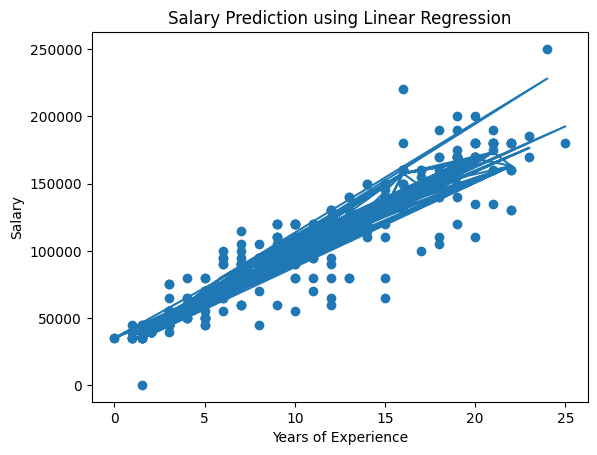

In [ ]:
plt.scatter(X_train, y_train)
plt.plot(X_train, model.predict(X_train))
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction using Linear Regression")
plt.show()

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

# Make sure your trained model variable is named: model

def predict_salary(experience):
    prediction = model.predict([[experience]])
    return f"Predicted Salary: {round(prediction[0], 2)}"

app = gr.Interface(
    fn=predict_salary,
    inputs=gr.Number(label="Enter Years of Experience"),
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Salary Prediction App",
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1c5fe660ed9c44e951.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
df = pd.get_dummies(df, drop_first=True)

In [ ]:
X = df.drop("Salary", axis=1)
y = df["Salary"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
df = df.dropna()

In [ ]:
X = df.drop("Salary", axis=1)
y = df["Salary"]

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)

In [ ]:
df = pd.get_dummies(df, drop_first=True)

In [ ]:
df = pd.get_dummies(df, drop_first=True)
df = df.dropna()

X = df.drop("Salary", axis=1)
y = df["Salary"]

In [ ]:
df = pd.get_dummies(df, drop_first=True)
df = df.dropna()

X = df.drop("Salary", axis=1)
y = df["Salary"]

model.fit(X, y)

LinearRegression()

In [ ]:
import gradio as gr
import pandas as pd

# Save feature column names
feature_columns = X.columns

def predict_salary(age, experience, gender_male, edu_masters, edu_phd):

    input_data = pd.DataFrame([[
        age,
        experience,
        gender_male,
        edu_masters,
        edu_phd
    ]], columns=feature_columns)

    prediction = model.predict(input_data)
    return f"Predicted Salary: {round(prediction[0], 2)}"


app = gr.Interface(
    fn=predict_salary,
    inputs=[
        gr.Number(label="Age"),
        gr.Number(label="Years of Experience"),
        gr.Radio([0,1], label="Gender (Male=1, Female=0)"),
        gr.Radio([0,1], label="Masters (1=yes,0=no)"),
        gr.Radio([0,1], label="PhD (1=yes,0=no)")
    ],
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Advanced Salary Prediction App"
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7a96dc34854f581c33.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print(X.columns)

Index(['Age', 'Years of Experience', 'Gender_Male', 'Education Level_Master's',
       'Education Level_PhD', 'Job Title_Accountant',
       'Job Title_Administrative Assistant', 'Job Title_Business Analyst',
       'Job Title_Business Development Manager',
       'Job Title_Business Intelligence Analyst',
       ...
       'Job Title_Supply Chain Manager', 'Job Title_Technical Recruiter',
       'Job Title_Technical Support Specialist', 'Job Title_Technical Writer',
       'Job Title_Training Specialist', 'Job Title_UX Designer',
       'Job Title_UX Researcher', 'Job Title_VP of Finance',
       'Job Title_VP of Operations', 'Job Title_Web Developer'],
      dtype='object', length=178)


In [ ]:
def predict_salary(age, experience, gender, masters, phd):

    input_dict = {
        "Age": age,
        "Years of Experience": experience,
        "Gender_Male": gender,
        "Education Level_Masters": masters,
        "Education Level_PhD": phd
    }

    input_df = pd.DataFrame([input_dict])

    # Add missing columns automatically
    for col in X.columns:
        if col not in input_df.columns:
            input_df[col] = 0

    input_df = input_df[X.columns]

    prediction = model.predict(input_df)
    return f"Predicted Salary: {round(prediction[0], 2)}"

In [ ]:
print(X.columns)

Index(['Age', 'Years of Experience', 'Gender_Male', 'Education Level_Master's',
       'Education Level_PhD', 'Job Title_Accountant',
       'Job Title_Administrative Assistant', 'Job Title_Business Analyst',
       'Job Title_Business Development Manager',
       'Job Title_Business Intelligence Analyst',
       ...
       'Job Title_Supply Chain Manager', 'Job Title_Technical Recruiter',
       'Job Title_Technical Support Specialist', 'Job Title_Technical Writer',
       'Job Title_Training Specialist', 'Job Title_UX Designer',
       'Job Title_UX Researcher', 'Job Title_VP of Finance',
       'Job Title_VP of Operations', 'Job Title_Web Developer'],
      dtype='object', length=178)


In [ ]:
model.fit(X, y)

LinearRegression()

In [ ]:
print(X.columns)

Index(['Age', 'Years of Experience', 'Gender_Male', 'Education Level_Master's',
       'Education Level_PhD', 'Job Title_Accountant',
       'Job Title_Administrative Assistant', 'Job Title_Business Analyst',
       'Job Title_Business Development Manager',
       'Job Title_Business Intelligence Analyst',
       ...
       'Job Title_Supply Chain Manager', 'Job Title_Technical Recruiter',
       'Job Title_Technical Support Specialist', 'Job Title_Technical Writer',
       'Job Title_Training Specialist', 'Job Title_UX Designer',
       'Job Title_UX Researcher', 'Job Title_VP of Finance',
       'Job Title_VP of Operations', 'Job Title_Web Developer'],
      dtype='object', length=178)


In [ ]:
print(model.predict(input_df))

NameError: name 'input_df' is not defined

In [ ]:
sample = pd.DataFrame([{
    "Age": 25,
    "Years of Experience": 3,
    "Gender_Male": 1,
    "Education Level_Masters": 0,
    "Education Level_PhD": 0
}])

# Make sure column order matches
sample = sample[X.columns]

print(model.predict(sample))""

SyntaxError: invalid syntax (3382855342.py, line 12)

In [ ]:
# ================================
# FULL SALARY PREDICTION PROJECT
# ================================

# 1️⃣ Import Libraries
import pandas as pd
import numpy as np
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 2️⃣ Load Dataset
df = pd.read_csv("/content/Salary Data.csv")   # change path if needed

# 3️⃣ Handle Missing Values
df = df.dropna()

# 4️⃣ Encode Categorical Columns
df = pd.get_dummies(df, drop_first=True)

# 5️⃣ Define Features & Target
X = df.drop("Salary", axis=1)
y = df["Salary"]

# 6️⃣ Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7️⃣ Train Model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model R2 Score:", r2_score(y_test, model.predict(X_test)))

# 8️⃣ Gradio Prediction Function
def predict_salary(*inputs):
    input_dict = dict(zip(X.columns, inputs))
    input_df = pd.DataFrame([input_dict])
    prediction = model.predict(input_df)
    return f"Predicted Salary: {round(prediction[0], 2)}"

# 9️⃣ Dynamic Input Fields
inputs = []
for col in X.columns:
    inputs.append(gr.Number(label=col))

# 🔟 Launch Gradio App
app = gr.Interface(
    fn=predict_salary,
    inputs=inputs,
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Advanced Salary Prediction App"
)

app.launch()

Model R2 Score: 0.8522475952130883
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://89f19d0bd9bc25e876.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================
# SALARY PREDICTION (ALL COLUMNS)
# ================================

# 1️⃣ Import Libraries
import pandas as pd
import numpy as np
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 2️⃣ Load Dataset
df = pd.read_csv("/content/Salary Data.csv")  # change path if needed

# 3️⃣ Handle Missing Values
df = df.fillna(df.mean(numeric_only=True))

# 4️⃣ Convert Categorical Columns Automatically
df = pd.get_dummies(df)

# 5️⃣ Separate Features and Target
X = df.drop("Salary", axis=1)
y = df["Salary"]

# 6️⃣ Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7️⃣ Train Model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model R2 Score:", r2_score(y_test, model.predict(X_test)))

# 8️⃣ Gradio Prediction Function
def predict_salary(*inputs):
    input_data = pd.DataFrame([inputs], columns=X.columns)
    prediction = model.predict(input_data)
    return f"Predicted Salary: {round(prediction[0], 2)}"

# 9️⃣ Create Dynamic Input Fields
gradio_inputs = []
for col in X.columns:
    gradio_inputs.append(gr.Number(label=col))

# 🔟 Launch Gradio App
app = gr.Interface(
    fn=predict_salary,
    inputs=gradio_inputs,
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Salary Prediction App (All Features)"
)

app.launch()

Model R2 Score: 0.8519902641944997
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://77aeec5ffd0b2d4fc6.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ================================
# SALARY PREDICTION WITH GRADIO
# ================================

# 1️⃣ Import Libraries
import pandas as pd
import numpy as np
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 2️⃣ Load Your CSV File
df = pd.read_csv("/content/Salary Data.csv")

# 3️⃣ Handle Missing Values
df = df.fillna(df.mean(numeric_only=True))

# 4️⃣ Convert Categorical Columns Automatically
df = pd.get_dummies(df)

# 5️⃣ Separate Features & Target
X = df.drop("Salary", axis=1)
y = df["Salary"]

# 6️⃣ Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7️⃣ Train Model
model = LinearRegression()
model.fit(X_train, y_train)

print("Model R2 Score:", r2_score(y_test, model.predict(X_test)))

# 8️⃣ Gradio Prediction Function
def predict_salary(*inputs):
    input_df = pd.DataFrame([inputs], columns=X.columns)
    prediction = model.predict(input_df)
    return f"Predicted Salary: {round(prediction[0], 2)}"

# 9️⃣ Create Dynamic Input Fields
gr_inputs = [gr.Number(label=col) for col in X.columns]

# 🔟 Launch App
app = gr.Interface(
    fn=predict_salary,
    inputs=gr_inputs,
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Salary Prediction App"
)

app.launch()

Model R2 Score: 0.8519902641944997
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e977249813bebce2dc.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
